# Modelo 2: CNN + LSTM, 2 canales (Fpz-Cz + Pz-Oz), configuración V1 

In [1]:
import os
import re
import glob
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve,
)
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

In [2]:
import os, numpy as np

NPZ_PATH = os.path.expanduser("~/Desktop/TFM/datos_procesados/datos_procesados_2canales.npz")
data = np.load(NPZ_PATH)

X_train_norm, y_train = data["X_train_norm"], data["y_train"]
X_val_norm,   y_val   = data["X_val_norm"],   data["y_val"]
X_test_norm,  y_test  = data["X_test_norm"],  data["y_test"]

print("Train:", X_train_norm.shape, "| Val:", X_val_norm.shape, "| Test:", X_test_norm.shape)

Train: (50005, 3000, 2) | Val: (11534, 3000, 2) | Test: (12390, 3000, 2)


## Modelo 2: CNN + LSTM

In [3]:
def build_cnn_lstm(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(32, kernel_size=7, activation="relu", padding="same"),
        layers.MaxPooling1D(4),
        layers.Conv1D(64, kernel_size=7, activation="relu", padding="same"),
        layers.MaxPooling1D(4),
        layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_lstm = build_cnn_lstm(X_train_norm.shape[1:])
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 3000, 32)       │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 750, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 750, 64)        │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 187, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,249 (348.63 KB)

 Trainable params: 89,249 (348.63 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento — Configuración V1 (2 canales)

In [ ]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=30,
    batch_size=64,
    class_weight={0: 1.0, 1: (y_train == 0).sum() / max((y_train == 1).sum(), 1)},
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 87s 106ms/step - accuracy: 0.9557 - loss: 0.1244 - val_accuracy: 0.9488 - val_loss: 0.1462
Epoch 2/30
299/782 ━━━━━━━━━━━━━━━━━━━━ 44s 93ms/step - accuracy: 0.9720 - loss: 0.0853

In [ ]:
import os, json

RUN_DIR = os.path.expanduser("~/Desktop/TFM/CNN-1D/CNN1D_2canales_V2")
os.makedirs(RUN_DIR, exist_ok=True)

# Guarda el modelo entrenado
model.save(os.path.join(RUN_DIR, "modelo_baseline_cnn1d.keras"))

# Guarda el historial de entrenamiento (para las gráficas de pérdida/accuracy)
with open(os.path.join(RUN_DIR, "historial_entrenamiento.json"), "w") as f:
    json.dump(history.history, f)

print("Modelo e historial guardados en:", RUN_DIR)

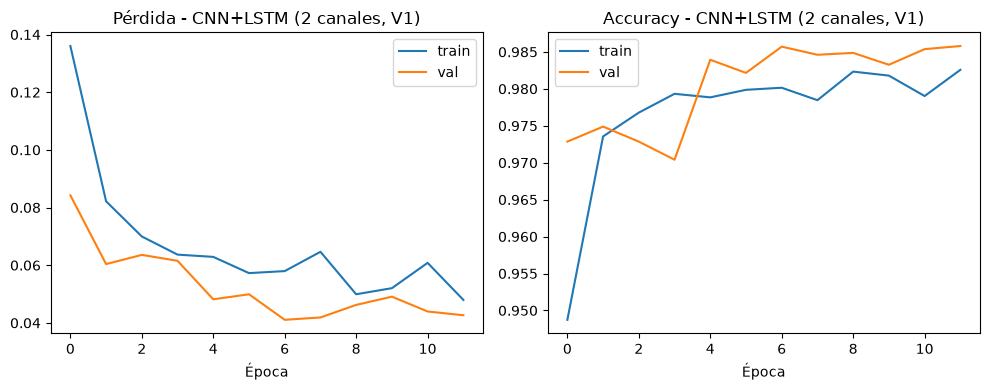

In [6]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_lstm.history["loss"], label="train")
plt.plot(history_lstm.history["val_loss"], label="val")
plt.title("Pérdida - CNN+LSTM (2 canales, V1)")
plt.xlabel("Época")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_lstm.history["accuracy"], label="train")
plt.plot(history_lstm.history["val_accuracy"], label="val")
plt.title("Accuracy - CNN+LSTM (2 canales, V1)")
plt.xlabel("Época")
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "curvas_entrenamiento_cnn_lstm_2canales.png"),
            dpi=150, bbox_inches="tight")
plt.show()

## Evaluación en el conjunto de test

381/381 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step
              precision    recall  f1-score   support

     Vigilia      0.990     0.961     0.975      6747
       Sueño      0.954     0.988     0.970      5440

    accuracy                          0.973     12187
   macro avg      0.972     0.974     0.973     12187
weighted avg      0.974     0.973     0.973     12187

ROC-AUC: 0.996


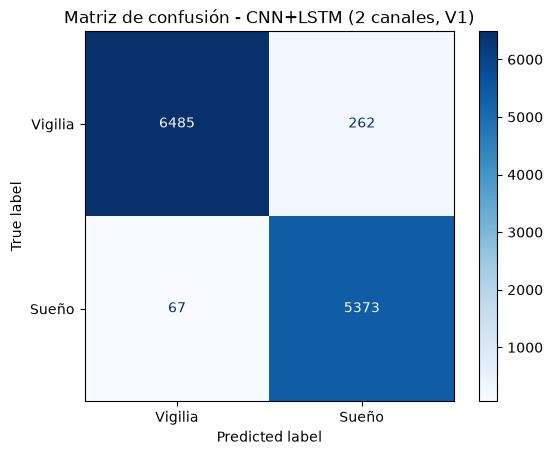

In [7]:
y_pred_prob_lstm = model_lstm.predict(X_test_norm).ravel()
y_pred_lstm = (y_pred_prob_lstm >= 0.5).astype(int)

print(classification_report(y_test, y_pred_lstm, target_names=["Vigilia", "Sueño"], digits=3))

roc_auc_lstm = roc_auc_score(y_test, y_pred_prob_lstm)
print(f"ROC-AUC: {roc_auc_lstm:.3f}")

cm_lstm = confusion_matrix(y_test, y_pred_lstm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lstm, display_labels=["Vigilia", "Sueño"])
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - CNN+LSTM (2 canales, V1)")
plt.savefig(os.path.join(IMAGES_DIR, "matriz_confusion_cnn_lstm_2canales.png"),
            dpi=150, bbox_inches="tight")
plt.show()

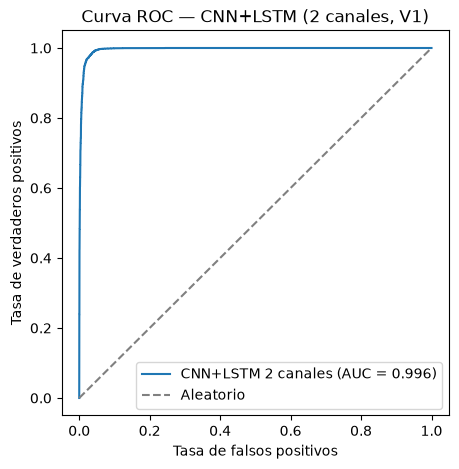

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob_lstm)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"CNN+LSTM 2 canales (AUC = {roc_auc_lstm:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — CNN+LSTM (2 canales, V1)")
plt.legend()
plt.savefig(os.path.join(IMAGES_DIR, "roc_curve_cnn_lstm_2canales.png"),
            dpi=150, bbox_inches="tight")
plt.show()